# 02 - Custom characteristics and quintile factor portfolios

Characteristics are formed at month-end t from information available at t; quintiles earn month t+1 returns. These are frictionless academic long-short returns, not investable strategies and not replications of the official French factors.

In [1]:
import logging

import pandas as pd
from IPython.display import Image, display

from factors import pipeline as pl
from factors.data import DataUnavailableError  # noqa: F401 - used by the real-data cells

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 160, "display.max_columns", 20)

def show(ctx, nn, name):
    display(Image(filename=str(ctx.fig(nn, name))))

## SYNTHETIC (all four characteristics; fundamentals are point-in-time by construction)

In [2]:
syn = pl.Context('synthetic', 'fast')
r = pl.stage_custom_factors(syn)
r['tear'][['signal', 'weighting', 'n_months', 'ann_mean', 'ann_vol', 'sharpe_ann', 't_mean_hac', 'max_drawdown']].round(3)

,signal,weighting,n_months,ann_mean,ann_vol,sharpe_ann,t_mean_hac,max_drawdown
0,value,ew,98,0.021,0.177,0.120,0.397,-0.486
1,value,vw,98,0.009,0.193,0.048,0.152,-0.524
2,momentum,ew,86,0.050,0.244,0.206,0.585,-0.473
3,momentum,vw,86,0.056,0.263,0.212,0.550,-0.612
4,low_vol,ew,93,-0.000,0.100,-0.001,-0.003,-0.184
5,low_vol,vw,93,0.056,0.138,0.408,0.989,-0.296
6,quality,ew,98,0.073,0.137,0.531,1.414,-0.280
7,quality,vw,98,0.053,0.168,0.317,0.779,-0.447


In [3]:
r['comparison']

,custom,reference,reference_source,n_months,correlation,start,end
0,value_ew,value,TRUE synthetic style factor returns,98,0.725016,2012-02-29,2020-03-31
1,momentum_ew,momentum,TRUE synthetic style factor returns,86,0.864177,2013-02-28,2020-03-31
2,quality_ew,quality,TRUE synthetic style factor returns,98,0.714316,2012-02-29,2020-03-31


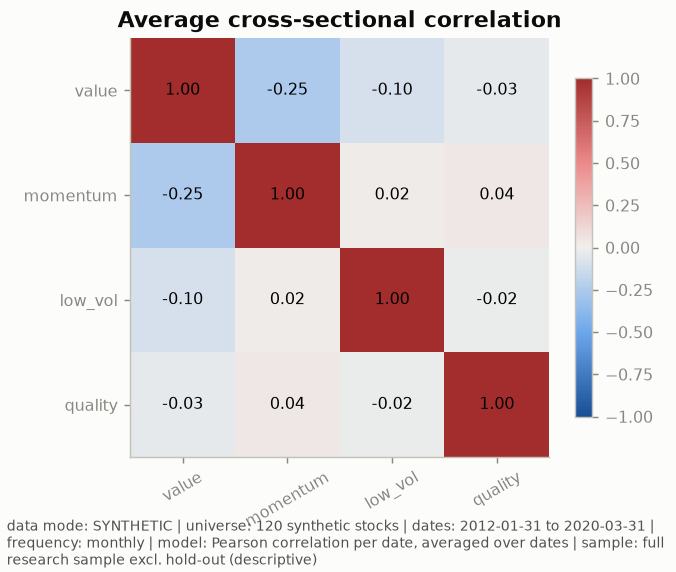

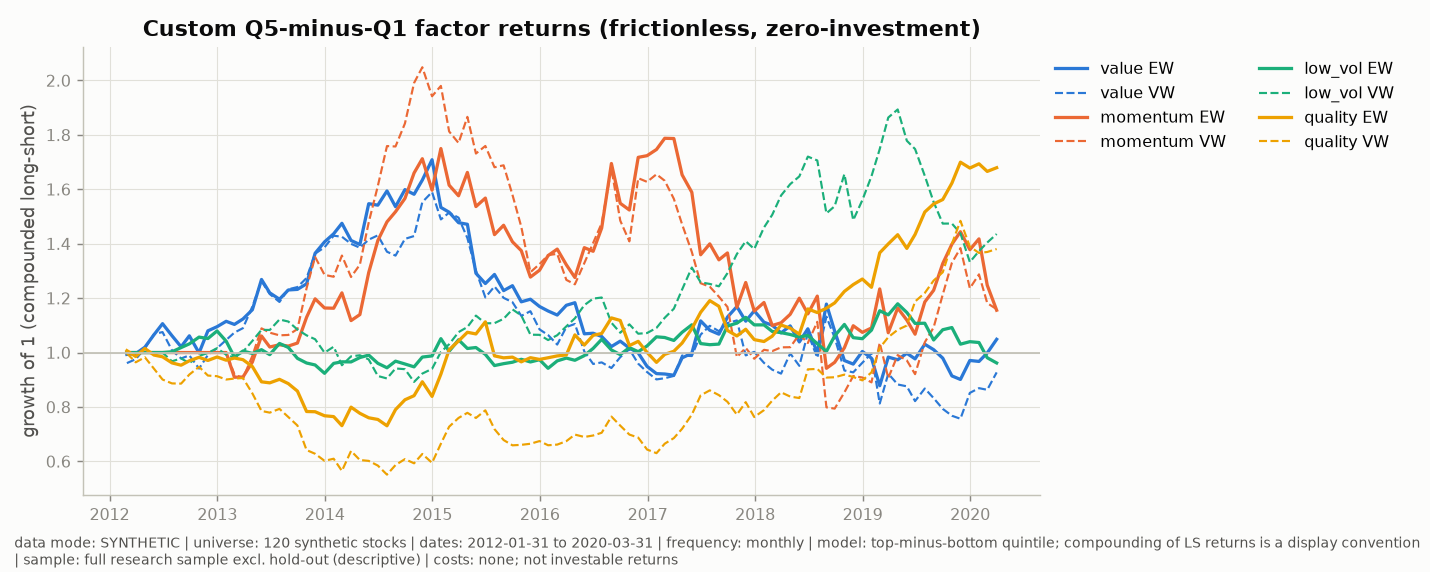

In [4]:
show(syn, '05b', 'characteristic_correlations')
show(syn, '07', 'custom_factor_cumulative')

## REAL (price-only: momentum and low volatility; current large caps -> survivorship bias)

,signal,weighting,n_months,ann_mean,sharpe_ann,t_mean_hac
0,momentum,ew,160,0.010,0.062,0.249
1,low_vol,ew,166,-0.125,-0.583,-2.316


,custom,reference,reference_source,n_months,correlation,start,end
0,momentum_ew,MOM,Kenneth French US factors,160,0.859472,2011-02-28,2024-05-31
1,low_vol_ew,MKT_RF_ff3,Kenneth French US factors,166,-0.640869,2010-08-31,2024-05-31


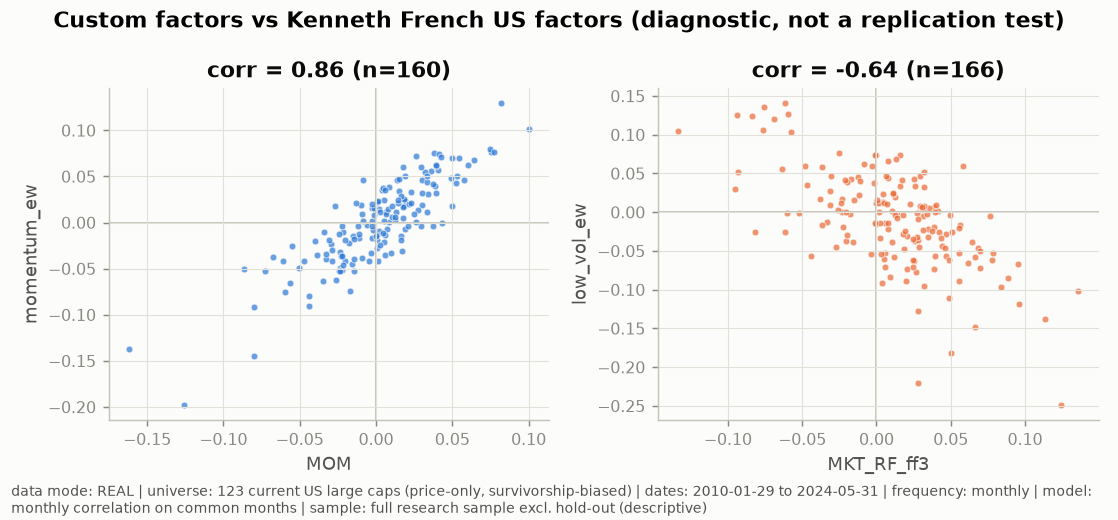

In [5]:
try:
    real = pl.Context('real')
    rr = pl.stage_custom_factors(real)
    display(rr['tear'][['signal', 'weighting', 'n_months', 'ann_mean', 'sharpe_ann', 't_mean_hac']].round(3))
    display(rr['comparison'])
    show(real, '08', 'published_factor_comparison')
except DataUnavailableError as e:
    print('REAL data not cached - skipped:', e)